# 02 · Ángulo de Cobb con `compute-Cobb-angle.py` sobre las máscaras de SPIDER

**Propósito.** Ejecutar sin modificar su lógica el script público de DIAGNijmegen (`cobb-angle-algorithm`, el método de van der Graaf *et al.* 2024) sobre las máscaras de referencia de SPIDER, para tener una primera corrida reproducible y verificada del algoritmo. Es un paso técnico de reproducción, no un análisis clínico.

**Lo que este cuaderno NO hace.** No usa las imágenes de RM (el script solo necesita las máscaras), no segmenta nada, no valida el ángulo contra un Cobb medido por personas y no detecta ni clasifica escoliosis. Los ángulos salen de las máscaras manuales de SPIDER, en decúbito y solo en la región lumbar visible, así que no son comparables con un Cobb de radiografía de pie ni sirven para estimar prevalencia. Uso exclusivo en investigación.

**Qué calcula el script.** Para cada disco intervertebral de la máscara (etiquetas mayores de 200) ajusta un plano a su cara superior y otro a su cara inferior, toma la inclinación de esos planos en el plano coronal y, con `largest_angle = True`, devuelve el mayor ángulo entre la cara inferior de un disco y la superior de otro más craneal. Si una máscara no tiene discos, el script asigna 9999.

**Fuentes.** Script: [DIAGNijmegen/cobb-angle-algorithm](https://github.com/DIAGNijmegen/cobb-angle-algorithm), commit `72c712f31e1f3069aef77b98b20af448bbc5615a`, Apache-2.0. Dependencia: [DIAGNijmegen/Tiger](https://github.com/DIAGNijmegen/Tiger), commit `4c63f6d58ed3f8e7a0cec04b0352949f7b512919` (rama `stable` el 15-oct-2026). Método: van der Graaf JW *et al.* *Eur Radiol* 2024, [PMC11364572](https://pmc.ncbi.nlm.nih.gov/articles/PMC11364572/). Datos: SPIDER, doi:[10.5281/zenodo.10159290](https://doi.org/10.5281/zenodo.10159290), v4, CC-BY 4.0.

**Carpetas en Drive.**
- Entrada: `PRL/content/datos/spider/masks/` (las mismas máscaras del cuaderno 01; no se duplican).
- Copia del script y sus huellas: `PRL/content/datos/compute-Cobb-angle/`.
- Resultados: `PRL/salidas/resultados_semana1/02_compute-Cobb-angle/`.

**Duración.** Unos 14 s por máscara, es decir cerca de una hora y media para las 447. El cuaderno guarda cada resultado al terminarlo: si Colab se desconecta, basta volver a ejecutar todo y continúa donde iba.

## Antes de ejecutar: datos necesarios

Este cuaderno **no descarga los datos**. Antes de correrlo hay que obtener SPIDER desde Zenodo (registro [10.5281/zenodo.10159290](https://doi.org/10.5281/zenodo.10159290), versión v4, licencia CC-BY 4.0) y guardarlo en Google Drive con esta estructura exacta:

| Archivo | Ruta en Drive | ¿Obligatorio? |
|-|-|-|
| `masks.zip` (≈ 58 MB) | `MyDrive/PRL/content/datos/spider/masks/masks.zip` | Sí |
| `overview.csv` | `MyDrive/PRL/content/datos/spider/overview.csv` | Sí |
| Imágenes `.mha` (de `images.zip`, ≈ 3,7 GB) | `MyDrive/PRL/content/datos/spider/images/` | No; solo para ver la RM debajo de la máscara en la vista previa |

La celda 4 comprueba que la MD5 de `masks.zip` sea `49861ff25a0108b3b69d0ce808ae51dc` y se detiene si no coincide o si el archivo no está. Si las máscaras no están descomprimidas, la celda 4 las descomprime en `datos/spider/masks/`.

Los resultados se escriben en `MyDrive/PRL/salidas/resultados_semana1/02_compute-Cobb-angle/`. La celda 5 procesa las 447 máscaras y en Colab gratuito tarda alrededor de hora y media; si se interrumpe, al volver a ejecutarla continúa con las series que no estén ya en `angulos_cobb.csv` de esa carpeta.

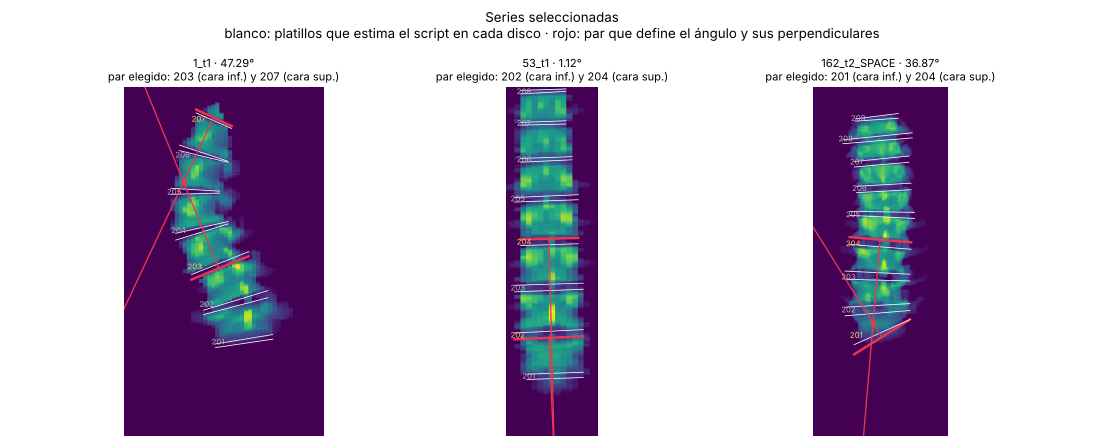

In [1]:
# 1. Dependencias: Tiger fijado al commit verificado (no a la rama, que puede moverse)
!pip -q install "git+https://github.com/DIAGNijmegen/Tiger.git@4c63f6d58ed3f8e7a0cec04b0352949f7b512919" openpyxl

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.1/72.1 kB 4.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.7/51.7 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.5/81.5 MB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.8/67.8 MB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.0/28.0 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━

In [3]:
# 2. Configuración
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
DIR_SPIDER = DIR_PRL / "content" / "datos" / "spider"
DIR_SCRIPT = DIR_PRL / "content" / "datos" / "compute-Cobb-angle"
DIR_SALIDA = DIR_PRL / "salidas" / "resultados_semana1" / "02_compute-Cobb-angle"
DIR_FIGURAS = DIR_SALIDA / "figuras"
DIR_LOCAL = Path("/content/mascaras_spider")     # copia local temporal: leer de Drive 447 veces es lento

COMMIT_SCRIPT = "72c712f31e1f3069aef77b98b20af448bbc5615a"
COMMIT_TIGER = "4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
SHA256_SCRIPT = "4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849"   # verificado el 1 y el 15-oct-2026
MD5_MASKS_ZIP = "49861ff25a0108b3b69d0ce808ae51dc"   # descarga verificada contra Zenodo el 2-oct-2026
N_ESPERADO = 447                                      # series de SPIDER según el cuaderno 01

assert DIR_SPIDER.exists(), f"No existe {DIR_SPIDER}; revisa con !ls /content/drive/MyDrive/PRL/content/datos"
for d in (DIR_SCRIPT, DIR_FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
print("Entrada:", DIR_SPIDER, "\nScript:", DIR_SCRIPT, "\nSalida:", DIR_SALIDA)

Mounted at /content/drive
Entrada: /content/drive/MyDrive/PRL/content/datos/spider 
Script: /content/drive/MyDrive/PRL/content/datos/compute-Cobb-angle 
Salida: /content/drive/MyDrive/PRL/salidas/resultados_semana1/02_compute-Cobb-angle


## Script fijado y verificado

Se descarga `compute-Cobb-angle.py` del commit fijado y se comprueba su SHA-256 contra el valor verificado. Si no coincide, el cuaderno se detiene: significaría que no estamos corriendo el mismo código que quedó registrado en `docs/fuentes_externas.md`.

**Única adaptación técnica (no cambia el método).** El script usa `np.linalg.eig`, que en NumPy 2 (la versión de Colab) devuelve los vectores propios como números complejos aunque la matriz sea simétrica, y eso rompe `np.rad2deg`. Se agrega una línea que toma la parte real, que es exacta porque la parte imaginaria es cero. Antes de adoptarla se comparó en cinco máscaras (51_t2, 55_t2_SPACE, 56_t2, 57_t1, 57_t2) contra el script **sin modificar** ejecutado con NumPy 1.26: los ángulos coincidieron hasta la decimotercera cifra decimal. Además, la ruta de entrada y de salida, que en el original son marcadores (`path/to/...`), se reemplazan por las carpetas de Drive. Las dos versiones del script y sus huellas quedan guardadas en `content/datos/compute-Cobb-angle/`.

In [4]:
# 3. Descargar el script del commit fijado, verificarlo y preparar la versión ejecutable
import hashlib, requests

def sha256_de(datos: bytes) -> str:
    return hashlib.sha256(datos).hexdigest()

url = f"https://raw.githubusercontent.com/DIAGNijmegen/cobb-angle-algorithm/{COMMIT_SCRIPT}/compute-Cobb-angle.py"
original = requests.get(url, timeout=60).content
sha_obtenido = sha256_de(original)
print("SHA-256 obtenido:", sha_obtenido)
assert sha_obtenido == SHA256_SCRIPT, "El script descargado NO coincide con el verificado; no continuar."

texto = original.decode("utf-8")
LINEA_EIG = "    eigenvalues, eigenvectors = np.linalg.eig(matrix)\n"
PARCHE = "    eigenvalues, eigenvectors = eigenvalues.real, eigenvectors.real  # adaptación a NumPy 2 (ver cuaderno 02)\n"
assert texto.count(LINEA_EIG) == 1
ejecutable = texto.replace(LINEA_EIG, LINEA_EIG + PARCHE)

(DIR_SCRIPT / "compute-Cobb-angle.py").write_bytes(original)
(DIR_SCRIPT / "compute-Cobb-angle_numpy2.py").write_text(ejecutable, encoding="utf-8")
(DIR_SCRIPT / "compute-Cobb-angle.py.sha256").write_text(f"{sha_obtenido}  compute-Cobb-angle.py\n")
(DIR_SCRIPT / "compute-Cobb-angle_numpy2.py.sha256").write_text(
    f"{sha256_de(ejecutable.encode('utf-8'))}  compute-Cobb-angle_numpy2.py\n")
(DIR_SCRIPT / "LEEME.txt").write_text(
    "compute-Cobb-angle.py: copia exacta de DIAGNijmegen/cobb-angle-algorithm, commit " + COMMIT_SCRIPT + " (Apache-2.0).\n"
    "compute-Cobb-angle_numpy2.py: la misma copia con una línea agregada en PCA() que toma la parte real de\n"
    "np.linalg.eig para que funcione con NumPy 2. Ver notebooks/02_compute_cobb_angle.ipynb.\n"
    "Los archivos .sha256 se verifican con: sha256sum -c <archivo>.sha256\n", encoding="utf-8")
print("Guardado en", DIR_SCRIPT, "->", sorted(p.name for p in DIR_SCRIPT.iterdir()))

SHA-256 obtenido: 4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849
Guardado en /content/drive/MyDrive/PRL/content/datos/compute-Cobb-angle -> ['LEEME.txt', 'compute-Cobb-angle.py', 'compute-Cobb-angle.py.sha256', 'compute-Cobb-angle_numpy2.py', 'compute-Cobb-angle_numpy2.py.sha256']


## Máscaras: verificación y copia local

Se usan las máscaras que el cuaderno 01 ya descomprimió en Drive. Primero se comprueba que `masks.zip` sigue teniendo la MD5 verificada contra Zenodo y que cada `.mha` descomprimido es idéntico a su versión dentro del zip; así queda demostrado que la entrada es la de SPIDER v4 sin alteraciones. Después se copian a una carpeta local de Colab para que la lectura sea rápida.

In [5]:
# 4. Verificar las máscaras contra masks.zip y copiarlas a disco local
import zipfile, shutil

def md5_archivo(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

zip_masks = next((p for p in (DIR_SPIDER / "masks.zip", DIR_SPIDER / "masks" / "masks.zip") if p.exists()), None)
assert zip_masks is not None, "No encontré masks.zip en datos/spider ni en datos/spider/masks"
md5_zip = md5_archivo(zip_masks)
print("MD5 de masks.zip:", md5_zip, "| coincide con la verificada:", md5_zip == MD5_MASKS_ZIP)
assert md5_zip == MD5_MASKS_ZIP

en_drive = {p.name: p for p in (DIR_SPIDER / "masks").rglob("*.mha")}
if not en_drive:   # el cuaderno 01 no se ha corrido: descomprimir aquí
    with zipfile.ZipFile(zip_masks) as z:
        z.extractall(DIR_SPIDER / "masks")
    en_drive = {p.name: p for p in (DIR_SPIDER / "masks").rglob("*.mha")}

DIR_LOCAL.mkdir(parents=True, exist_ok=True)
distintos = []
with zipfile.ZipFile(zip_masks) as z:
    miembros = {Path(n).name: n for n in z.namelist() if n.endswith(".mha")}
    for nombre, miembro in miembros.items():
        datos_zip = z.read(miembro)
        ruta = en_drive.get(nombre)
        if ruta is None or hashlib.md5(ruta.read_bytes()).hexdigest() != hashlib.md5(datos_zip).hexdigest():
            distintos.append(nombre)
        (DIR_LOCAL / nombre).write_bytes(datos_zip)   # la copia local sale del zip verificado

mascaras = sorted(DIR_LOCAL.glob("*.mha"))
print(f"{len(miembros)} máscaras en el zip | {len(en_drive)} en Drive | {len(distintos)} distintas o faltantes en Drive")
if distintos:
    print("Revisar en Drive (se usa la copia del zip):", distintos[:10])
assert len(mascaras) == N_ESPERADO, f"Se esperaban {N_ESPERADO} máscaras y hay {len(mascaras)}"

MD5 de masks.zip: 49861ff25a0108b3b69d0ce808ae51dc | coincide con la verificada: True
447 máscaras en el zip | 447 en Drive | 0 distintas o faltantes en Drive


## Nomenclatura de las etiquetas en las máscaras de SPIDER

Cada estructura de una máscara de SPIDER tiene un número entero: las vértebras van de 1 en adelante, el canal medular es 100 y los discos van de 201 en adelante. El script usa esta convención para separarlas (vértebras < 100, canal = 100, discos > 200). El sacro no está segmentado.

La numeración va **de abajo hacia arriba**: la vértebra lumbar más caudal es la 1. Según el artículo del dataset, este número **no es una etiqueta anatómica**: la vértebra 1 no es necesariamente L5, porque una vértebra de transición lumbosacra ocurre en el 35,5 % de la población y una sexta lumbar en el 6,6 %, y el campo de visión de estas RM no permite contar los niveles desde arriba (van der Graaf *et al.*, *Sci Data* 2024;11:264, doi:[10.1038/s41597-024-03090-w](https://doi.org/10.1038/s41597-024-03090-w)).

Al ordenar por altura las estructuras de varias máscaras (185_t1, 1_t1 y 162_t2_SPACE), el disco 20k aparece siempre justo debajo de la vértebra k. Así, el disco 201 es el que queda entre la vértebra lumbar más caudal y el sacro. Esta relación se comprobó en esas máscaras; el artículo no la enuncia de forma explícita.

Equivalencia **solo si la anatomía es típica** (cinco lumbares, sin vértebra de transición). Es una inferencia, no un dato del dataset:

| Etiqueta SPIDER | Nivel con anatomía típica |
|-|-|
| vértebra 1 / disco 201 | L5 / L5–S1 |
| vértebra 2 / disco 202 | L4 / L4–L5 |
| vértebra 3 / disco 203 | L3 / L3–L4 |
| vértebra 4 / disco 204 | L2 / L2–L3 |
| vértebra 5 / disco 205 | L1 / L1–L2 |
| vértebra 6 / disco 206 | T12 / T12–L1 |
| vértebra 7 en adelante | torácicas que alcanzan a entrar en el campo de visión |

En este cuaderno los niveles se nombran siempre con la etiqueta de SPIDER (por ejemplo, "disco 201, el más caudal; probablemente L5–S1"), nunca solo con el nombre anatómico.

## Vista previa de las máscaras

Antes de correr el script se muestra cómo son las máscaras de un estudio en sus tres secuencias. Arriba, el corte sagital con más estructura segmentada, sobre la RM cuando la imagen está en `datos/spider/images/`; abajo, la proyección coronal de la máscara, que es la vista en la que el script mide el ángulo. Cambia `ESTUDIO_EJEMPLO` para ver otro estudio. Esta celda no calcula nada.

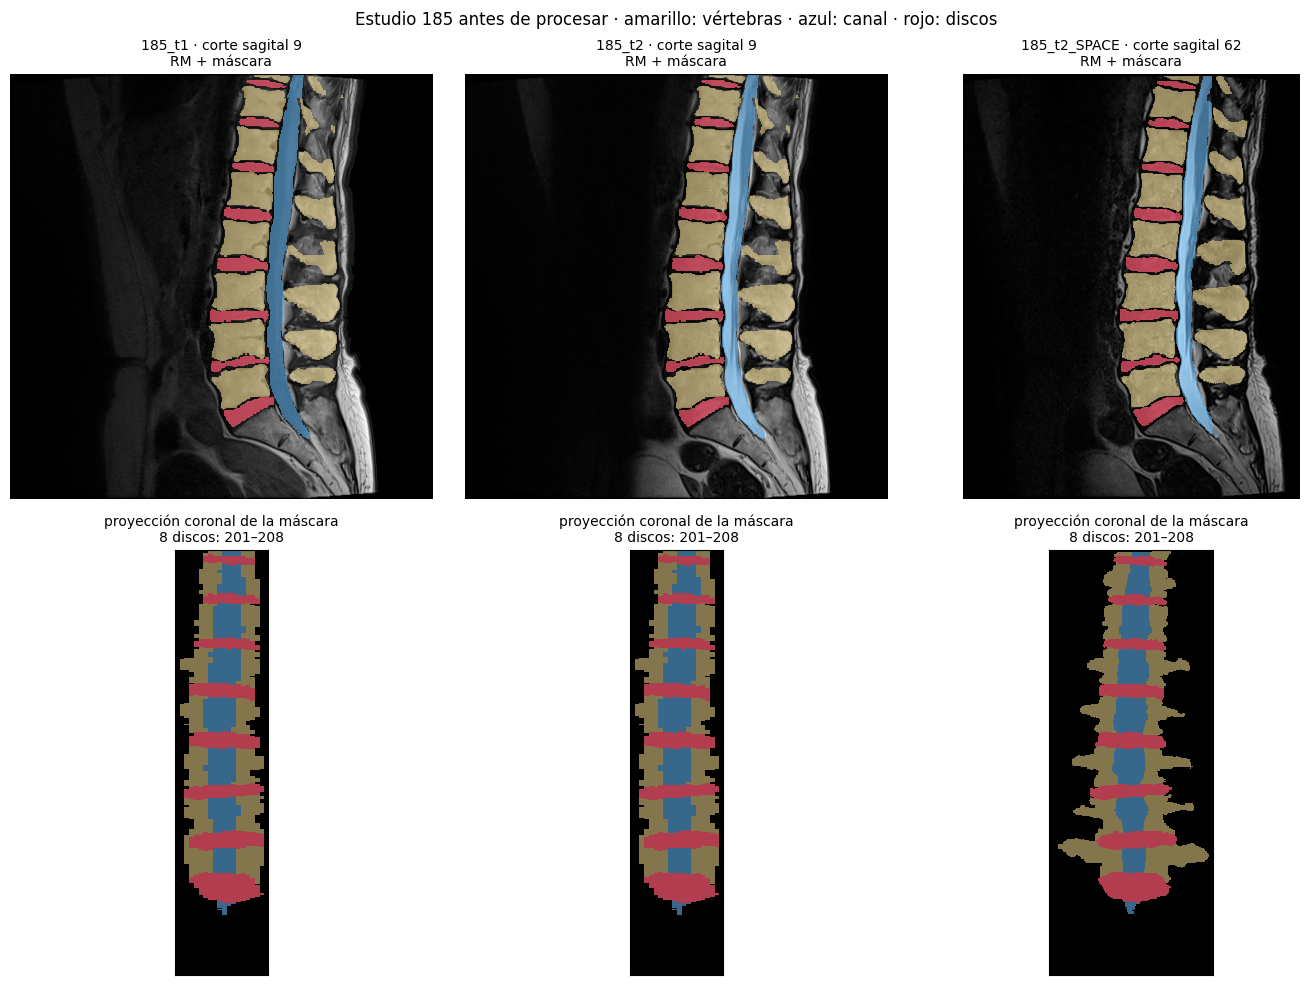

In [6]:
# 4b. Vista previa: cómo son las máscaras ANTES de procesarlas (un estudio, sus tres secuencias)
ESTUDIO_EJEMPLO = "185"   # @param {type:"string"}
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")   # la celda 5 dejó matplotlib en modo sin pantalla (Agg)
import numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tiger.io import read_image
from tiger.resampling import reorient_image

def leer_reorientado(ruta, interpolacion):
    arr, hdr = read_image(ruta)
    return reorient_image(arr, hdr, interpolation=interpolacion)   # misma orientación que usa el script

def colorear(mascara):
    """0 fondo, 1 vértebra (<100), 2 canal (100), 3 disco (>200): la convención de etiquetas de SPIDER."""
    c = np.zeros_like(mascara, dtype=np.uint8)
    c[(mascara > 0) & (mascara < 100)] = 1
    c[mascara == 100] = 2
    c[mascara > 200] = 3
    return c

CMAP_ESTRUCTURAS = ListedColormap([(0, 0, 0, 0), (0.95, 0.85, 0.55, 0.55), (0.40, 0.75, 1.0, 0.55), (1.0, 0.35, 0.45, 0.70)])
secuencias = [s for s in ("t1", "t2", "t2_SPACE") if (DIR_LOCAL / f"{ESTUDIO_EJEMPLO}_{s}.mha").exists()]
assert secuencias, f"El estudio {ESTUDIO_EJEMPLO} no tiene máscaras en {DIR_LOCAL}"

fig, axes = plt.subplots(2, len(secuencias), figsize=(4.6 * len(secuencias), 10), squeeze=False)
for j, s in enumerate(secuencias):
    m, hm = leer_reorientado(DIR_LOCAL / f"{ESTUDIO_EJEMPLO}_{s}.mha", "nearest")
    ruta_img = DIR_SPIDER / "images" / f"{ESTUDIO_EJEMPLO}_{s}.mha"
    x = int(np.argmax((m > 0).sum(axis=(1, 2))))          # corte sagital con más estructura segmentada
    sx, sy, sz = hm.spacing
    ax = axes[0, j]
    if ruta_img.exists():
        im, _ = leer_reorientado(ruta_img, "linear")
        ax.imshow(im[x].T, cmap="gray", origin="lower", aspect=sz / sy)
        fondo = "RM + máscara"
    else:
        fondo = "solo máscara (imagen no está en Drive)"
    ax.imshow(colorear(m[x]).T, cmap=CMAP_ESTRUCTURAS, origin="lower", aspect=sz / sy, interpolation="nearest", vmin=0, vmax=3)
    ax.set_title(f"{ESTUDIO_EJEMPLO}_{s} · corte sagital {x}\n{fondo}", fontsize=10); ax.axis("off")
    ax = axes[1, j]
    proyeccion = np.max(colorear(m), axis=1)                # proyección coronal (de frente)
    ax.imshow(proyeccion.T, cmap=CMAP_ESTRUCTURAS, origin="lower", aspect=sz / sx, interpolation="nearest", vmin=0, vmax=3)
    ax.set_facecolor("black"); ax.invert_xaxis()
    discos = sorted(int(v) for v in np.unique(m) if v > 200)
    ax.set_title(f"proyección coronal de la máscara\n{len(discos)} discos: {discos[0]}–{discos[-1]}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Estudio {ESTUDIO_EJEMPLO} antes de procesar · amarillo: vértebras · azul: canal · rojo: discos", fontsize=12)
plt.tight_layout(); plt.show()

## Ejecución

El script original procesa todas las máscaras de una carpeta en un solo bucle y al final escribe `results.xlsx` con los ángulos **sin el nombre de la serie**, además de un `results.csv` vacío (escribe la lista `angles_manual`, que nunca se llena). Para no depender de eso y poder retomar si Colab se desconecta, aquí se ejecuta el script tal cual sobre **una máscara a la vez** (cada una en su propia carpeta temporal) y se lee su diccionario `all_scans`, que asocia la serie con su ángulo. La figura que genera el script se guarda en `figuras/` con su nombre original. Cada fila se agrega a `angulos_cobb.csv` en cuanto termina, junto con las etiquetas de disco que encontró, el tiempo y cualquier error. Ese archivo es el registro crudo de la corrida; la tabla con secuencia y escáner se escribe aparte en `angulos_cobb_con_metadatos.csv`.

In [7]:
# 5. Ejecutar el script sobre cada máscara (retoma donde iba si se interrumpe)
import csv, time, tempfile, traceback, io, contextlib
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")                   # el script llama plt.show(); así no se intenta abrir 447 ventanas
import matplotlib.pyplot as plt
from tiger.io import read_image

CSV_ANGULOS = DIR_SALIDA / "angulos_cobb.csv"
COLUMNAS = ["serie", "angulo_cobb_grados", "n_discos", "etiquetas_disco", "estado", "segundos", "detalle"]
hechas = set(pd.read_csv(CSV_ANGULOS, dtype=str)["serie"]) if CSV_ANGULOS.exists() else set()
if not CSV_ANGULOS.exists():
    with open(CSV_ANGULOS, "w", newline="") as f:
        csv.writer(f).writerow(COLUMNAS)

codigo = (DIR_SCRIPT / "compute-Cobb-angle_numpy2.py").read_text(encoding="utf-8")
pendientes = [m for m in mascaras if m.stem not in hechas]
print(f"Ya procesadas: {len(hechas)} | pendientes: {len(pendientes)}")

for i, ruta in enumerate(pendientes, 1):
    t0 = time.time()
    etiquetas = sorted(int(x) for x in np.unique(read_image(ruta)[0]) if x > 200)
    with tempfile.TemporaryDirectory() as tmp_in, tempfile.TemporaryDirectory() as tmp_out:
        shutil.copy(ruta, Path(tmp_in) / ruta.name)
        fuente = (codigo
                  .replace("mask_path = Path('path/to/spine/segmentations')", f"mask_path = Path({tmp_in!r})")
                  .replace("image_path = Path('path/to/output/images')", f"image_path = Path({tmp_out!r})"))
        ns = {"__name__": "compute_cobb_angle"}
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(fuente, "compute-Cobb-angle_numpy2.py", "exec"), ns)
            angulo = float(ns["all_scans"][ruta.stem])
            estado = "sin_discos (el script asigna 9999)" if angulo == 9999 else "ok"
            detalle = ""
            png = Path(tmp_out) / f"{ruta.stem}.png"
            if png.exists():
                shutil.copy(png, DIR_FIGURAS / png.name)
        except Exception as e:
            angulo, estado, detalle = np.nan, "error", f"{type(e).__name__}: {e}"
            traceback.print_exc()
        finally:
            plt.close("all")
    with open(CSV_ANGULOS, "a", newline="") as f:
        csv.writer(f).writerow([ruta.stem, angulo, len(etiquetas), " ".join(map(str, etiquetas)),
                                estado, round(time.time() - t0, 1), detalle])
    if i % 25 == 0 or i == len(pendientes):
        print(f"{i}/{len(pendientes)} · última: {ruta.stem} = {angulo:.2f}° ({estado})")

Ya procesadas: 447 | pendientes: 0


## Resumen descriptivo

Las tablas de abajo solo describen lo que devolvió el script. No hay estándar de referencia en SPIDER para el ángulo de Cobb, así que **no se calcula exactitud, ni sensibilidad, ni se usa ningún umbral para llamar "escoliosis" a una serie.** Se reportan por separado las series sin discos o con error, porque no deben entrar a ningún promedio.

In [8]:
# 6. Tabla final, unida a overview.csv para conservar secuencia y escáner
res = pd.read_csv(CSV_ANGULOS, dtype={"serie": str})[COLUMNAS]
res = res.drop_duplicates("serie", keep="last").sort_values("serie", key=lambda s: s.str.split("_").str[0].astype(int))
ov = pd.read_csv(DIR_SPIDER / "overview.csv", dtype={"new_file_name": str})
ov["serie"] = ov["new_file_name"].astype(str).str.strip()
res["estudio"] = res["serie"].str.split("_", n=1).str[0]
sufijo = res["serie"].str.split("_", n=1).str[1].str.lower()
res["secuencia"] = np.where(sufijo.str.contains("space", na=False), "t2_SPACE", sufijo)
columnas_ov = [c for c in ["serie", "subset", "Manufacturer", "ManufacturerModelName", "MagneticFieldStrength"] if c in ov]
res = res.merge(ov[columnas_ov], on="serie", how="left")
res.to_csv(DIR_SALIDA / "angulos_cobb_con_metadatos.csv", index=False)   # angulos_cobb.csv queda como registro crudo

validas = res[res["estado"] == "ok"]
print("Series por estado:\n" + res["estado"].value_counts().to_string())
resumen = (validas.groupby("secuencia")["angulo_cobb_grados"]
           .describe(percentiles=[.25, .5, .75]).round(2))
print("\nÁngulo devuelto por el script, por secuencia (solo series ok):")
print(resumen.to_string())
resumen.to_csv(DIR_SALIDA / "resumen_por_secuencia.csv")

Series por estado:
estado
ok    447

Ángulo devuelto por el script, por secuencia (solo series ok):
           count  mean   std   min   25%   50%    75%    max
secuencia                                                   
t1         196.0  8.73  7.00  1.12  4.25  6.62  10.29  47.29
t2         210.0  8.51  6.86  0.98  4.25  6.67  10.06  47.29
t2_SPACE    41.0  9.86  8.47  1.87  4.84  6.59  10.44  36.87


## Misma persona, distinta secuencia

En SPIDER un mismo estudio suele tener T1, T2 y a veces T2 SPACE. Al revisar los casos extremos se encontró que la máscara de T1 y la de T2 de un mismo estudio pueden ser el mismo archivo (por ejemplo, `1_t1.mha` y `1_t2.mha` tienen la misma MD5). Cuando eso ocurre, el ángulo es idéntico por construcción y la diferencia T1 − T2 no mide variabilidad del algoritmo. Por eso la celda 7 se interpreta junto con la 7b, que cuenta cuántas parejas usan la misma máscara y recalcula T1 − T2 solo con las parejas cuyas máscaras son distintas. Las comparaciones con T2 SPACE sí usan máscaras diferentes. Todo esto es descriptivo, no una medida formal de concordancia (para eso harían falta ICC de acuerdo absoluto y Bland-Altman con su protocolo).

In [9]:
# 7. Diferencias entre secuencias de un mismo estudio
ancho = validas.pivot_table(index="estudio", columns="secuencia", values="angulo_cobb_grados")
pares = [(a, b) for a, b in [("t1", "t2"), ("t2", "t2_SPACE"), ("t1", "t2_SPACE")] if a in ancho and b in ancho]
filas = []
for a, b in pares:
    d = (ancho[a] - ancho[b]).dropna()
    filas.append({"par": f"{a} − {b}", "n_estudios": len(d), "media_dif": d.mean(), "de_dif": d.std(),
                  "mediana_abs": d.abs().median(), "max_abs": d.abs().max()})
entre_secuencias = pd.DataFrame(filas).round(2)
print(entre_secuencias.to_string(index=False))
entre_secuencias.to_csv(DIR_SALIDA / "diferencias_entre_secuencias.csv", index=False)
ancho.round(3).to_csv(DIR_SALIDA / "angulos_por_estudio_y_secuencia.csv")

          par  n_estudios  media_dif  de_dif  mediana_abs  max_abs
      t1 − t2         190      -0.05    0.78         0.00     7.43
t2 − t2_SPACE          39      -0.09    1.53         0.56     6.84
t1 − t2_SPACE          39      -0.46    1.15         0.56     3.33


In [10]:
# 7b. ¿Cuántas parejas de un mismo estudio usan exactamente la misma máscara?
import hashlib, itertools
md5_por_serie = {p.stem: hashlib.md5(p.read_bytes()).hexdigest() for p in mascaras}
filas = []
for estudio, grupo in res.groupby("estudio"):
    series = dict(zip(grupo["secuencia"], grupo["serie"]))
    for a, b in [("t1", "t2"), ("t2", "t2_SPACE"), ("t1", "t2_SPACE")]:
        if a in series and b in series:
            filas.append({"estudio": estudio, "par": f"{a} − {b}",
                          "mascara_identica": md5_por_serie[series[a]] == md5_por_serie[series[b]]})
identicas = pd.DataFrame(filas)
conteo = identicas.groupby("par")["mascara_identica"].agg(parejas="count", identicas="sum")
conteo["porcentaje_identicas"] = (100 * conteo["identicas"] / conteo["parejas"]).round(1)
print(conteo.to_string())
identicas.to_csv(DIR_SALIDA / "parejas_mascara_identica.csv", index=False)

# Diferencias T1 − T2 solo entre parejas con máscaras DISTINTAS (las idénticas dan 0 por construcción)
distintas = identicas[(identicas["par"] == "t1 − t2") & ~identicas["mascara_identica"]]["estudio"]
d = (ancho.loc[ancho.index.isin(distintas), "t1"] - ancho.loc[ancho.index.isin(distintas), "t2"]).dropna()
print(f"\nT1 − T2 con máscaras distintas: n = {len(d)} · media {d.mean():.2f}° · DE {d.std():.2f}° · "
      f"mediana |dif| {d.abs().median():.2f}° · máx |dif| {d.abs().max():.2f}°")

               parejas  identicas  porcentaje_identicas
par                                                    
t1 − t2            190        107                  56.3
t1 − t2_SPACE       39          0                   0.0
t2 − t2_SPACE       39          0                   0.0

T1 − T2 con máscaras distintas: n = 83 · media -0.12° · DE 1.17° · mediana |dif| 0.48° · máx |dif| 7.43°


In [ ]:
# 8. Registro del entorno (para docs/fuentes_externas.md y para reproducir la corrida)
import json, sys, platform, datetime, importlib.metadata as md_
import skimage
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "numpy": np.__version__, "scikit-image": skimage.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "tiger": md_.version("tiger") if any(d.metadata["Name"].lower() == "tiger" for d in md_.distributions()) else "instalado desde git",
    "tiger_commit": COMMIT_TIGER, "script_commit": COMMIT_SCRIPT, "script_sha256": SHA256_SCRIPT,
    "adaptacion": "parte real de np.linalg.eig en PCA() para NumPy 2; validada contra NumPy 1.26 en 5 máscaras",
    "masks_zip_md5": md5_zip, "n_mascaras": len(mascaras), "mascaras_distintas_en_drive": distintos,
    "largest_angle": True, "resolucion_resampleo_mm": [0.5, 0.5, 0.5],
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False))
print(json.dumps(entorno, indent=2, ensure_ascii=False))
print("\nArchivos en la salida:", sorted(p.name for p in DIR_SALIDA.iterdir()), "| figuras:", len(list(DIR_FIGURAS.glob("*.png"))))

## Inspección visual: qué hizo el script

Las líneas del panel son los planos que el propio script ajusta a la cara superior e inferior de cada disco (objetos `Disc`, funciones `best_fitting_plane` y `plane_to_tangent`), y el par en rojo es el que el script eligió con `largest_angle = True`. El script original ya dibuja esas mismas líneas en su PNG (blancas y rojas); aquí solo se cambian los colores y se agregan las etiquetas de disco. Debajo del panel se imprime, para las caras elegidas, su inclinación sagital y el ángulo coronal que calcula el script.

**Hallazgo a revisar (15-oct-2026): máscaras compartidas y máscaras incompletas.**

De las 190 parejas T1/T2 de un mismo estudio, 107 (56,3 %) usan exactamente la misma máscara (misma MD5), así que su diferencia de ángulo es cero por construcción. Por eso la desviación estándar de 0,78° de la tabla de la celda 7 subestima la variabilidad. En las 83 parejas con máscaras distintas, la diferencia T1 − T2 tuvo media −0,12°, DE 1,17°, mediana de la diferencia absoluta 0,48° y máximo 7,43°. Las parejas con T2 SPACE (39 con T1 y 39 con T2) no compartieron máscara en ningún caso.

Que T1 y T2 compartan máscara no se explica del todo con lo que describe el artículo de SPIDER. Según los autores, las máscaras de T1 y T2 se obtuvieron remuestreando la segmentación de T2 SPACE solo en los 20 estudios del centro universitario que se anotaron a mano al inicio, y 15 de ellos quedaron en el conjunto de prueba que no se publicó; el resto de las máscaras se generó con una red de segmentación y se corrigió a mano (van der Graaf *et al.*, *Sci Data* 2024, doi:[10.1038/s41597-024-03090-w](https://doi.org/10.1038/s41597-024-03090-w)). Al agrupar los estudios por escáner, las parejas idénticas aparecen en 19 de los 39 estudios con T2 SPACE, en 83 de los 90 del grupo Philips Ingenia 3,0 T y en 5 de los 61 restantes. El artículo no explica por qué ocurre, y la pregunta quedó planteada a los autores en el issue.

El máximo de 7,43° corresponde al estudio 35: la máscara de `35_t2` solo tiene 3 discos (201–203) y da 15,41°, mientras que la de `35_t1` tiene 9 discos (201–209) y da 7,97°. La diferencia no se explica por la secuencia sino por la cobertura de la máscara: con menos niveles, el script elige el máximo entre otros pares de discos. Junto con el caso del disco 201 en el estudio 162 (sección de inspección visual), esto muestra dos factores que cambian el ángulo sin que cambie la columna: la inclinación sagital del disco más caudal y el número de niveles segmentados. Ambos son descriptivos y falta cuantificar en cuántas de las 447 series ocurren.

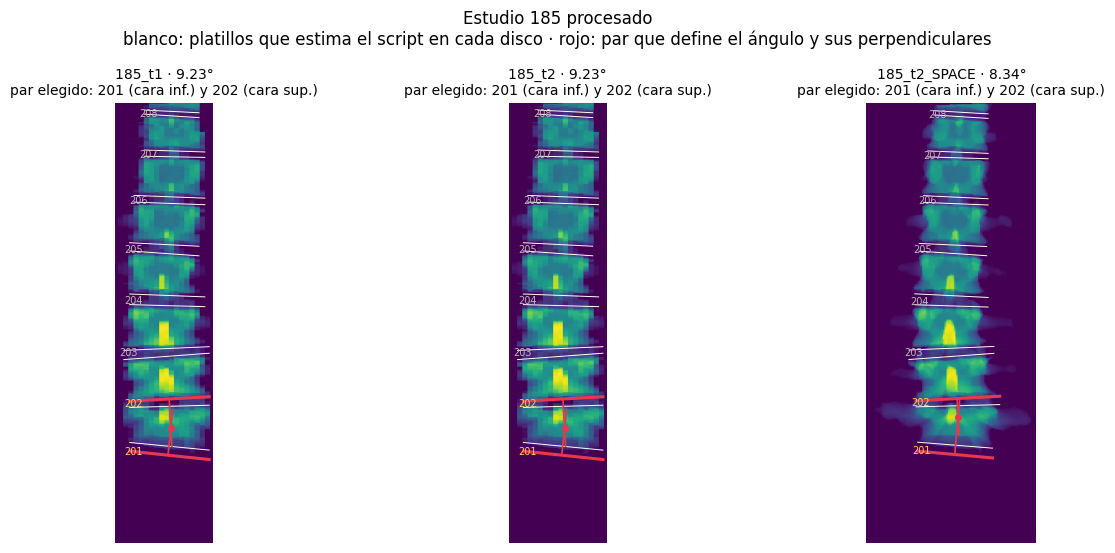

Caras usadas para el ángulo (inclinación sagital alta + ángulo coronal alto = revisar):
       serie  disco     cara  inclinacion_sagital  angulo_coronal_script  elegido
      185_t1    201 inferior                -28.7                   -6.0     True
      185_t1    202 superior                 -6.8                    3.2     True
      185_t2    201 inferior                -28.7                   -6.0     True
      185_t2    202 superior                 -6.8                    3.2     True
185_t2_SPACE    201 inferior                -29.0                   -5.2     True
185_t2_SPACE    202 superior                 -6.4                    3.2     True


In [14]:
# 9. Qué hizo el script: platillos estimados y par de discos elegido
#    SERIES_PANEL = None  -> muestra las series del estudio de ejemplo (celda 4b)
#    SERIES_PANEL = "extremos" -> mayor y menor ángulo por secuencia
#    SERIES_PANEL = ["162_t2_SPACE", "162_t2"] -> las series que quieras
SERIES_PANEL = None
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")   # la celda 5 dejó matplotlib en modo sin pantalla (Agg)
import io, contextlib, tempfile, shutil
import matplotlib.pyplot as plt

def ejecutar_script(serie):
    """Corre compute-Cobb-angle_numpy2.py sobre una máscara y devuelve su espacio de nombres (discos, planos, ángulo)."""
    with tempfile.TemporaryDirectory() as ti, tempfile.TemporaryDirectory() as to:
        shutil.copy(DIR_LOCAL / f"{serie}.mha", Path(ti) / f"{serie}.mha")
        fuente = (codigo.replace("mask_path = Path('path/to/spine/segmentations')", f"mask_path = Path({ti!r})")
                        .replace("image_path = Path('path/to/output/images')", f"image_path = Path({to!r})"))
        ns = {"__name__": "compute_cobb_angle"}
        mostrar_original, figuras_previas = plt.show, set(plt.get_fignums())
        plt.show = lambda *a, **k: None          # que no aparezca la figura propia del script, solo el panel
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(fuente, "compute-Cobb-angle_numpy2.py", "exec"), ns)
        finally:
            plt.show = mostrar_original
            for num in set(plt.get_fignums()) - figuras_previas:   # cierra solo la figura que abrió el script
                plt.close(num)
    return ns

def dibujar_perpendiculares(ax, disco_inf, disco_sup, color, ancho=1.2, estilo="-", extra_px=25):
    """Construcción clásica del Cobb: una perpendicular a cada platillo elegido y el punto donde se cruzan.
    Usa los mismos planos y normales del script (componentes x y z, que son los de la proyección coronal).
    Cada perpendicular llega hasta el cruce y sigue solo `extra_px` píxeles más. Si el cruce cae fuera de
    la imagen (ángulos pequeños, líneas casi paralelas), se dibujan tramos cortos sin marcar el cruce."""
    limite_x, limite_y = ax.get_xlim(), ax.get_ylim()           # se guardan con su orientación original
    (x0, x1), (y0, y1) = sorted(limite_x), sorted(limite_y)
    p1, n1 = disco_inf.point_L[[0, 2]], disco_inf.normal_L[[0, 2]]
    p2, n2 = disco_sup.point_U[[0, 2]], disco_sup.normal_U[[0, 2]]
    n1, n2 = n1 / np.linalg.norm(n1), n2 / np.linalg.norm(n2)
    matriz = np.column_stack([n1, -n2])
    cruce = None
    if abs(np.linalg.det(matriz)) > 1e-6:
        t, s = np.linalg.solve(matriz, p2 - p1)
        candidato = p1 + t * n1
        if x0 <= candidato[0] <= x1 and y0 <= candidato[1] <= y1:
            cruce = candidato
    if cruce is not None:
        for p in (p1, p2):
            direccion = (cruce - p) / (np.linalg.norm(cruce - p) or 1)
            extremo = cruce + direccion * extra_px
            ax.plot([p[0], extremo[0]], [p[1], extremo[1]], color=color, lw=ancho, ls=estilo)
        ax.plot(*cruce, "o", ms=4, color=color)
    else:
        tramo = 0.25 * (y1 - y0)                                  # tramo corto: 15 % del alto de la imagen
        for p, n, signo in ((p1, n1, 1), (p2, n2, -1)):          # hacia el centro de la columna
            hacia = n if np.dot(n, (p2 - p1) * signo) >= 0 else -n
            ax.plot([p[0], p[0] + hacia[0] * tramo], [p[1], p[1] + hacia[1] * tramo], color=color, lw=ancho, ls=estilo)
    ax.set_xlim(limite_x); ax.set_ylim(limite_y)
    return cruce

def inclinaciones(normal):
    n = normal / np.linalg.norm(normal)
    return np.degrees(np.arctan2(n[1], n[2])), np.degrees(np.arctan(n[0] / n[2]))   # sagital, coronal (la del script)

if SERIES_PANEL is None:
    series = [f"{ESTUDIO_EJEMPLO}_{s}" for s in secuencias]; titulo = f"Estudio {ESTUDIO_EJEMPLO} procesado"
elif SERIES_PANEL == "extremos":
    series = []
    for s in ("t1", "t2", "t2_SPACE"):
        sub = validas[validas["secuencia"] == s]
        if len(sub):
            series += [sub.loc[sub["angulo_cobb_grados"].idxmax(), "serie"], sub.loc[sub["angulo_cobb_grados"].idxmin(), "serie"]]
    series = series[0::2] + series[1::2]; titulo = "Mayor (arriba) y menor (abajo) ángulo por secuencia"
else:
    series = list(SERIES_PANEL); titulo = "Series seleccionadas"

columnas = min(3, len(series)); filas_fig = int(np.ceil(len(series) / columnas))
fig, axes = plt.subplots(filas_fig, columnas, figsize=(4.6 * columnas, 5.6 * filas_fig), squeeze=False)
detalle = []
for ax, serie in zip(axes.ravel(), series):
    ns = ejecutar_script(serie)
    labels, discos = ns["labels"], ns["all_discs"]
    d_inf, d_sup = labels[ns["index_highest_vertebra"]], labels[ns["index_lowest_vertebra"]]
    ax.imshow(ns["image2D"].T)                 # mismo mapa de color que usa el script
    for lab, d in discos.items():
        for punto, normal, cara, elegido in ((d.point_L, d.normal_L, "inferior", lab == d_inf),
                                             (d.point_U, d.normal_U, "superior", lab == d_sup)):
            x, z = ns["plane_to_tangent"](d.verts, punto, normal)
            ax.plot(x, z, color="#e8384f" if elegido else "white", lw=2.2 if elegido else 0.7)
            sag, cor = inclinaciones(normal)
            detalle.append({"serie": serie, "disco": lab, "cara": cara, "inclinacion_sagital": round(sag, 1),
                            "angulo_coronal_script": round(cor, 1), "elegido": elegido})
        ax.text(d.verts[:, 0].max() + 6, d.verts[:, 2].mean(), str(lab), fontsize=7, va="center",
                color="#ffd166" if lab in (d_inf, d_sup) else "#bbbbbb")
    dibujar_perpendiculares(ax, discos[d_inf], discos[d_sup], "#e8384f")
    ax.invert_yaxis(); ax.invert_xaxis(); ax.axis("off")
    ax.set_title(f"{serie} · {ns['angle']:.2f}°\npar elegido: {d_inf} (cara inf.) y {d_sup} (cara sup.)", fontsize=10)
for ax in axes.ravel()[len(series):]:
    ax.axis("off")
fig.suptitle(titulo + "\nblanco: platillos que estima el script en cada disco · rojo: par que define el ángulo y sus perpendiculares", fontsize=12)
plt.tight_layout(); plt.show()

ultimo_panel = fig                                   # la celda 10 guarda este panel si la ejecutas
detalle_panel = pd.DataFrame(detalle)
print("Caras usadas para el ángulo (inclinación sagital alta + ángulo coronal alto = revisar):")
print(detalle_panel[detalle_panel["elegido"]].to_string(index=False))

In [12]:
# 10. Guardar el último panel generado (celda 9 u 11). Solo guarda si GUARDAR_PANEL = True.
GUARDAR_PANEL = False   # @param {type:"boolean"}
import datetime
if not GUARDAR_PANEL:
    print("No se guardó nada: marca GUARDAR_PANEL (o escribe True) y vuelve a ejecutar esta celda.")
else:
    DIR_REVISION = DIR_SALIDA / "paneles_revision"
    DIR_REVISION.mkdir(parents=True, exist_ok=True)
    marca = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    nombre = f"panel_{'_'.join(sorted(detalle_panel['serie'].unique()))[:80]}_{marca}"
    ultimo_panel.savefig(DIR_REVISION / f"{nombre}.png", dpi=150, facecolor="white", bbox_inches="tight")
    detalle_panel.to_csv(DIR_REVISION / f"{nombre}_planos.csv", index=False)
    print("Guardado:", DIR_REVISION / f"{nombre}.png")

No se guardó nada: marca GUARDAR_PANEL (o escribe True) y vuelve a ejecutar esta celda.


## **CELDA INTERACTIVA: Elige tú el par de discos**

Aquí no decide el script: eliges qué disco es el extremo inferior y cuál el superior, y el ángulo se calcula con la misma fórmula del script (cara superior del disco craneal menos cara inferior del disco caudal, en valor absoluto), usando los planos que el script ya ajustó. Así se puede comparar el ángulo "máximo" del script con el de un par elegido viendo la imagen, que es parecido a lo que hicieron van der Graaf et al. al medir con el algoritmo en los niveles elegidos por los lectores.

La selección se hace por disco porque los planos se ajustan sobre los discos. Por el orden de las etiquetas (ver la sección de nomenclatura), la cara inferior del disco 20a toca el platillo superior de la vértebra a−1 (el sacro, si a = 1) y la cara superior del disco 20b toca el platillo inferior de la vértebra b.

En el panel, rojo es tu par, naranja punteado es el par que eligió el script y azul el resto.

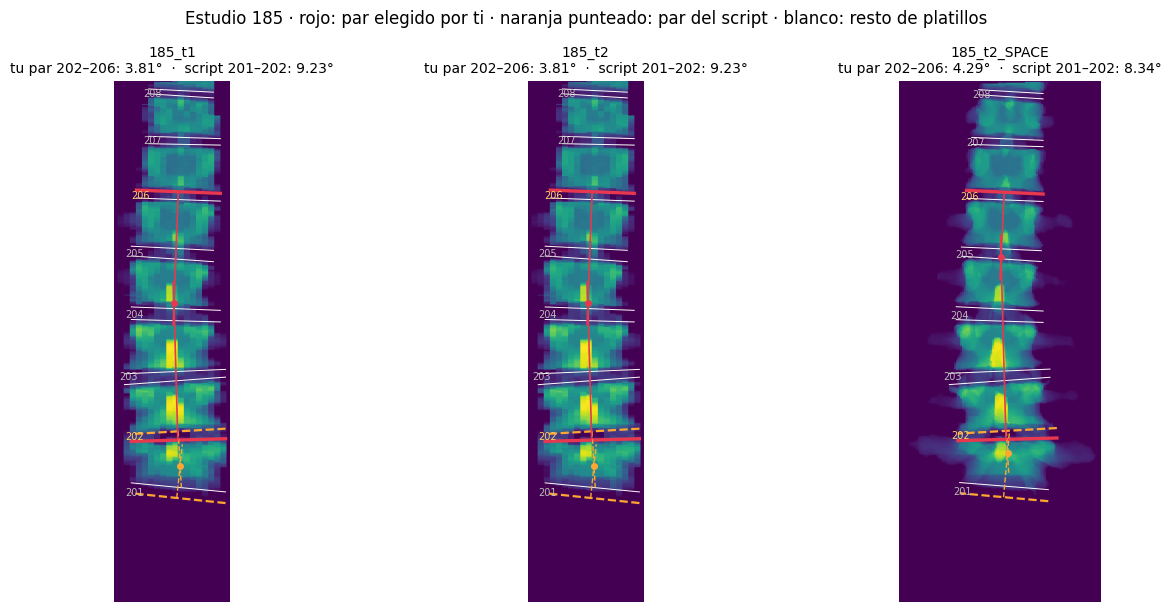

Caras usadas (inclinación sagital alta + ángulo coronal alto = revisar):
       serie  disco     cara  inclinacion_sagital  angulo_coronal_script                   uso
      185_t1    201 inferior                -28.7                   -6.0 elegido por el script
      185_t1    202 inferior                 -9.2                    1.6        elegido por ti
      185_t1    202 superior                 -6.8                    3.2 elegido por el script
      185_t1    206 superior                  5.2                   -2.2        elegido por ti
      185_t2    201 inferior                -28.7                   -6.0 elegido por el script
      185_t2    202 inferior                 -9.2                    1.6        elegido por ti
      185_t2    202 superior                 -6.8                    3.2 elegido por el script
      185_t2    206 superior                  5.2                   -2.2        elegido por ti
185_t2_SPACE    201 inferior                -29.0                   -5.2

In [15]:
# 11. Ángulo entre el par de discos que TÚ eliges (estudio de la celda 4b, todas sus secuencias)
DISCO_INFERIOR = 202   # @param {type:"integer"}
DISCO_SUPERIOR = 206   # @param {type:"integer"}
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

try:
    _cache_script
except NameError:
    _cache_script = {}                       # evita volver a correr el script sobre la misma serie

def script_en_cache(serie):
    if serie not in _cache_script:
        _cache_script[serie] = ejecutar_script(serie)   # funciones definidas en la celda 9
    return _cache_script[serie]

assert DISCO_INFERIOR < DISCO_SUPERIOR, "DISCO_INFERIOR debe ser más caudal (número menor) que DISCO_SUPERIOR"
series = [f"{ESTUDIO_EJEMPLO}_{s}" for s in secuencias]
fig, axes = plt.subplots(1, len(series), figsize=(4.8 * len(series), 6.2), squeeze=False)
filas = []
for ax, serie in zip(axes.ravel(), series):
    ns = script_en_cache(serie)
    labels, discos = ns["labels"], ns["all_discs"]
    auto_inf, auto_sup = labels[ns["index_highest_vertebra"]], labels[ns["index_lowest_vertebra"]]
    ax.imshow(ns["image2D"].T)
    if DISCO_INFERIOR not in discos or DISCO_SUPERIOR not in discos:
        ax.set_title(f"{serie}\nno tiene el disco {DISCO_INFERIOR if DISCO_INFERIOR not in discos else DISCO_SUPERIOR}"
                     f" (discos: {labels[0]}–{labels[-1]})", fontsize=10)
        ax.invert_yaxis(); ax.invert_xaxis(); ax.axis("off")
        continue
    # misma fórmula del script: cara superior del disco craneal − cara inferior del disco caudal, en valor absoluto
    angulo = abs(discos[DISCO_SUPERIOR].angle_U - discos[DISCO_INFERIOR].angle_L)
    for lab, d in discos.items():
        for punto, normal, cara in ((d.point_L, d.normal_L, "inferior"), (d.point_U, d.normal_U, "superior")):
            x, z = ns["plane_to_tangent"](d.verts, punto, normal)
            elegido = (lab == DISCO_INFERIOR and cara == "inferior") or (lab == DISCO_SUPERIOR and cara == "superior")
            automatico = (lab == auto_inf and cara == "inferior") or (lab == auto_sup and cara == "superior")
            if elegido:
                ax.plot(x, z, color="#e8384f", lw=2.4)
            elif automatico:
                ax.plot(x, z, color="#ffa630", lw=1.6, ls="--")
            else:
                ax.plot(x, z, color="white", lw=0.7)
            if elegido or automatico:
                sag, cor = inclinaciones(normal)                 # función definida en la celda 9
                filas.append({"serie": serie, "disco": lab, "cara": cara, "inclinacion_sagital": round(sag, 1),
                              "angulo_coronal_script": round(cor, 1),
                              "uso": "elegido por ti" + (" y por el script" if automatico else "") if elegido else "elegido por el script"})
        ax.text(d.verts[:, 0].max() + 6, d.verts[:, 2].mean(), str(lab), fontsize=7, va="center",
                color="#ffd166" if lab in (DISCO_INFERIOR, DISCO_SUPERIOR) else "#bbbbbb")
    dibujar_perpendiculares(ax, discos[auto_inf], discos[auto_sup], "#ffa630", ancho=1.0, estilo="--")
    dibujar_perpendiculares(ax, discos[DISCO_INFERIOR], discos[DISCO_SUPERIOR], "#e8384f")
    ax.invert_yaxis(); ax.invert_xaxis(); ax.axis("off")
    ax.set_title(f"{serie}\ntu par {DISCO_INFERIOR}–{DISCO_SUPERIOR}: {angulo:.2f}°  ·  script {auto_inf}–{auto_sup}: {ns['angle']:.2f}°",
                 fontsize=10)
fig.suptitle(f"Estudio {ESTUDIO_EJEMPLO} · rojo: par elegido por ti · naranja punteado: par del script · blanco: resto de platillos",
             fontsize=12)
plt.tight_layout(); plt.show()

ultimo_panel = fig                                       # la celda 10 guarda este panel si la ejecutas
detalle_panel = pd.DataFrame(filas)
print("Caras usadas (inclinación sagital alta + ángulo coronal alto = revisar):")
print(detalle_panel.to_string(index=False))

**Criterio de cierre.** El cuaderno corre de principio a fin con *Entorno de ejecución → Reiniciar y ejecutar todo*, `angulos_cobb.csv` tiene 447 filas (una por serie) y cada serie con estado `ok` tiene su figura en `figuras/`. Las series con estado distinto de `ok` se revisan una por una antes de usar los resultados.